# Phase 4: Evaluation & Comparative Analysis (with Bias Check)


In [18]:
import re
import html
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import (
    GroupShuffleSplit, train_test_split, GroupKFold, StratifiedKFold
)
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score
)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

DATA_FILE = "fakenewsnet_cleaned_final.csv"
SEEDS = list(range(5))      # number of random splits to average over
TEST_SIZE = 0.2

## 1. Load and prepare the data

In [19]:
df = pd.read_csv(DATA_FILE)

df["title"] = df["title"].fillna("").astype(str)
df["title"] = df["title"].apply(html.unescape).str.strip()
df["title"] = df["title"].str.replace(r"\s+", " ", regex=True)

df["y"] = pd.to_numeric(df["representation"], errors="coerce")      # 1 = fake, 0 = real
df = df[df["y"].isin([0, 1])].copy()
df["y"] = df["y"].astype(int)
df = df[df["title"] != ""].copy()

# remove titles with conflicting labels, then duplicate titles
conflict = df.groupby(df["title"].str.lower())["y"].transform("nunique")
df = df[conflict == 1].copy()
df["title_key"] = df["title"].str.lower()
df = df.drop_duplicates("title_key").drop(columns=["title_key"]).reset_index(drop=True)


def get_publisher(url):
    if not isinstance(url, str) or not url.strip():
        return None
    url = url.strip()
    if not url.startswith(("http://", "https://")):
        url = "https://" + url
    host = urlparse(url).netloc.lower().split(":")[0]
    if host.startswith("www."):
        host = host[4:]
    if not host:
        return None
    parts = host.split(".")
    if len(parts) >= 3 and len(parts[-1]) == 2 and parts[-2] in ("co", "com", "org", "net", "gov", "ac"):
        return ".".join(parts[-3:])
    return ".".join(parts[-2:]) if len(parts) >= 2 else host


df["publisher"] = df["news_url"].apply(get_publisher)
df = df.dropna(subset=["publisher"]).reset_index(drop=True)

# remove junk: non-news "publishers" and very short articles
NON_NEWS = {"wikipedia.org", "celebritynetworth.com", "instagram.com", "twitter.com",
            "facebook.com", "youtube.com", "amazon.com", "politifact.com"}
df = df[~df["publisher"].isin(NON_NEWS)]
df["article_text"] = df["article_text"].fillna("").astype(str).str.strip()
df = df[df["article_text"].str.split().str.len() >= 50].reset_index(drop=True)


def mask_publisher(text):
    text = str(text)
    text = re.sub(r"\b[\w-]+\.(com|net|org|co\.uk|info|tv)\b", " ", text, flags=re.IGNORECASE)
    text = re.sub(r"\s[\|–—-]\s*\S+(\s\S+)?$", " ", text)
    return re.sub(r"\s+", " ", text).strip()


df["title_masked"] = df["title"].apply(mask_publisher)
df["article_text_masked"] = df["article_text"].apply(mask_publisher)

# which fact-checking site the article came from
df["source"] = df["id"].astype(str).str.extract(r"^(gossipcop|politifact)")[0]

print("Rows:", len(df), "| publishers:", df["publisher"].nunique())
print("Fake:", (df["y"] == 1).sum(), "| Real:", (df["y"] == 0).sum())
print(df.groupby(["source", "y"]).size().unstack())

Rows: 2095 | publishers: 385
Fake: 548 | Real: 1547
y              0    1
source               
gossipcop   1477  474
politifact    70   74


## 2. Helper functions
Metrics, models and the two kinds of split.

In [20]:
def get_scores(model, X):
    """Continuous score for the fake class (needed for ROC-AUC)."""
    if hasattr(model, "decision_function"):
        return model.decision_function(X)
    return model.predict_proba(X)[:, 1]


def evaluate(y_true, y_pred, y_score):
    return {
        "acc": accuracy_score(y_true, y_pred),
        "bal_acc": balanced_accuracy_score(y_true, y_pred),
        "prec": precision_score(y_true, y_pred, zero_division=0),
        "rec": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_score),
    }


def make_models():
    return {
        "Logistic Regression": LogisticRegression(C=1.0, max_iter=1000, class_weight="balanced"),
        "Linear SVM": LinearSVC(C=0.5, class_weight="balanced"),
        "Naive Bayes": ComplementNB(alpha=0.5),
        "Majority baseline": DummyClassifier(strategy="most_frequent"),
    }


def new_vectorizer():
    return TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_features=50000)


def random_split(data, seed):
    return train_test_split(data, test_size=TEST_SIZE, random_state=seed, stratify=data["y"])


def publisher_split(data, seed):
    splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=seed)
    tr, te = next(splitter.split(data, groups=data["publisher"]))
    train, test = data.iloc[tr], data.iloc[te]
    assert set(train["publisher"]).isdisjoint(set(test["publisher"]))   # no shared publishers
    return train, test

# Part A - Model evaluation


In [21]:
TEXTS = {"title_masked": "title_masked", "body_masked": "article_text_masked"}
METRICS = ["acc", "bal_acc", "prec", "rec", "f1", "roc_auc"]

rows = []
for seed in SEEDS:
    for split_name, split_fn in [("random", random_split), ("held-out", publisher_split)]:
        train, test = split_fn(df, seed)
        for text_name, col in TEXTS.items():
            vec = new_vectorizer()                       # fitted on training data only
            X_train = vec.fit_transform(train[col])
            X_test = vec.transform(test[col])
            for model_name, model in make_models().items():
                model.fit(X_train, train["y"])
                pred = model.predict(X_test)
                rows.append({
                    "model": model_name, "text": text_name, "split": split_name, "seed": seed,
                    "n_test": len(test), "test_fake_rate": test["y"].mean(),
                    **evaluate(test["y"], pred, get_scores(model, X_test)),
                })
    print("finished seed", seed)

res = pd.DataFrame(rows)
res.to_csv("phase4_all_runs.csv", index=False)

finished seed 0
finished seed 1
finished seed 2
finished seed 3
finished seed 4


### A1. Average results (mean over seeds)

In [22]:
summary = res.groupby(["text", "model", "split"])[METRICS].mean().round(3)
print(summary)

print("\nStandard deviation over seeds (how stable the results are):")
print(res.groupby(["text", "model", "split"])[["f1", "bal_acc", "roc_auc"]].std().round(3))

print("\nTest set size and share of fake articles:")
print(res.groupby("split")[["n_test", "test_fake_rate"]].agg(["mean", "std"]).round(3))
summary.to_csv("phase4_summary.csv")

                                             acc  bal_acc   prec    rec     f1  roc_auc
text         model               split                                                 
body_masked  Linear SVM          held-out  0.814    0.726  0.661  0.546  0.594    0.825
                                 random    0.817    0.730  0.692  0.547  0.610    0.836
             Logistic Regression held-out  0.815    0.735  0.652  0.573  0.604    0.815
                                 random    0.822    0.740  0.699  0.567  0.625    0.836
             Majority baseline   held-out  0.737    0.500  0.000  0.000  0.000    0.500
                                 random    0.737    0.500  0.000  0.000  0.000    0.500
             Naive Bayes         held-out  0.756    0.541  0.880  0.085  0.153    0.749
                                 random    0.775    0.580  0.873  0.169  0.283    0.768
title_masked Linear SVM          held-out  0.759    0.709  0.534  0.606  0.558    0.785
                                

### A2. Does performance drop on unseen publishers?
`drop = random - held-out`. A **positive** drop means the model does worse on unseen publishers (the problem the project is about). A drop near zero or negative means no measurable penalty. The std column shows how much the drop varies between seeds. If it is bigger than the mean, the difference is mostly noise.

In [23]:
drops = []
for metric in ["f1", "bal_acc", "roc_auc"]:
    t = res.pivot_table(index=["text", "model", "seed"], columns="split", values=metric)
    t["drop"] = t["random"] - t["held-out"]
    d = t.groupby(["text", "model"])["drop"].agg(["mean", "std"]).round(3)
    d.columns = [f"{metric}_drop_mean", f"{metric}_drop_std"]
    drops.append(d)

drop_table = pd.concat(drops, axis=1)
print(drop_table)
drop_table.to_csv("phase4_drop_table.csv")

                                  f1_drop_mean  f1_drop_std  bal_acc_drop_mean  bal_acc_drop_std  roc_auc_drop_mean  roc_auc_drop_std
text         model                                                                                                                   
body_masked  Linear SVM                  0.015        0.089              0.004             0.034              0.010             0.030
             Logistic Regression         0.021        0.110              0.005             0.044              0.021             0.039
             Majority baseline           0.000        0.000              0.000             0.000              0.000             0.000
             Naive Bayes                 0.129        0.042              0.040             0.013              0.019             0.020
title_masked Linear SVM                 -0.002        0.092             -0.010             0.026             -0.007             0.037
             Logistic Regression         0.018        0.096   

### A3. Chart: balanced accuracy, random vs held-out (0.5 = guessing)

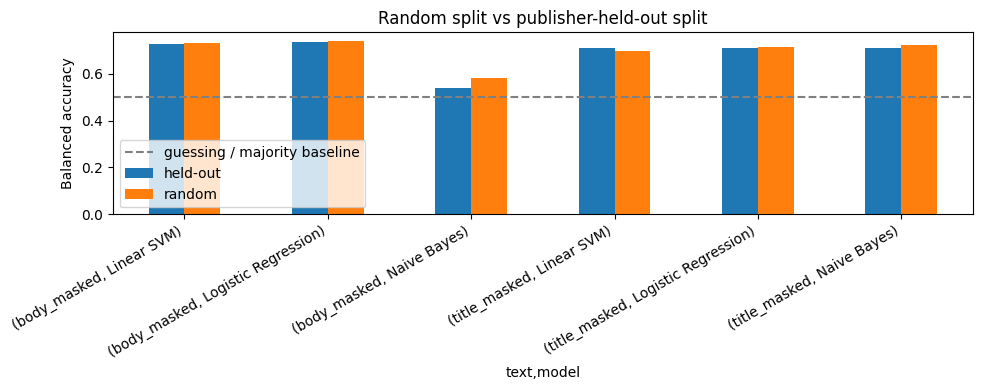

In [24]:
plot_df = (res[res["model"] != "Majority baseline"]
           .groupby(["text", "model", "split"])["bal_acc"].mean().unstack("split"))
ax = plot_df.plot(kind="bar", figsize=(10, 4))
ax.axhline(0.5, color="gray", linestyle="--", label="guessing / majority baseline")
ax.set_ylabel("Balanced accuracy")
ax.set_title("Random split vs publisher-held-out split")
ax.legend()
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("phase4_chart_models.png", dpi=150)
plt.show()

# Part B - Bias check


In [25]:
def tfidf_features(col):
    def featurize(train, test):
        vec = new_vectorizer()
        return vec.fit_transform(train[col]), vec.transform(test[col])
    return featurize


def publisher_features(train, test):
    """Uses ONLY the publisher name (no article text)."""
    enc = OneHotEncoder(handle_unknown="ignore")
    return enc.fit_transform(train[["publisher"]]), enc.transform(test[["publisher"]])


def cv_predict(featurize, splitter, groups=None):
    pred = np.zeros(len(df), dtype=int)
    score = np.zeros(len(df))
    for tr, te in splitter.split(df, df["y"], groups):
        X_tr, X_te = featurize(df.iloc[tr], df.iloc[te])
        model = LogisticRegression(C=1.0, max_iter=1000, class_weight="balanced")
        model.fit(X_tr, df["y"].iloc[tr])
        pred[te] = model.predict(X_te)
        score[te] = model.decision_function(X_te)
    return pred, score


random_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
group_cv = GroupKFold(n_splits=5)

pred_body = {
    "random": cv_predict(tfidf_features("article_text_masked"), random_cv),
    "held-out": cv_predict(tfidf_features("article_text_masked"), group_cv, groups=df["publisher"]),
}
pred_pub = {
    "random": cv_predict(publisher_features, random_cv),
    "held-out": cv_predict(publisher_features, group_cv, groups=df["publisher"]),
}
print("done")

done


### B1. Publisher-shortcut check
A model that sees **only the publisher name** and no article text should be useless. If it predicts fake/real well on the random split, then the publisher alone gives away the label, and any text model can take the same shortcut.

In [26]:
rows = []
for name, preds in [("Publisher name only", pred_pub), ("Masked body text (LR)", pred_body)]:
    for split_name, (pred, score) in preds.items():
        rows.append({"input": name, "split": split_name, **evaluate(df["y"], pred, score)})

shortcut = pd.DataFrame(rows).set_index(["input", "split"]).round(3)
print(shortcut)
shortcut.to_csv("phase4_publisher_shortcut.csv")

                                  acc  bal_acc   prec    rec     f1  roc_auc
input                 split                                                 
Publisher name only   random    0.738    0.635  0.500  0.418  0.455    0.701
                      held-out  0.738    0.500  0.000  0.000  0.000    0.515
Masked body text (LR) random    0.820    0.741  0.685  0.575  0.625    0.838
                      held-out  0.816    0.737  0.677  0.569  0.618    0.829


### B2. Is the model unfair to some publishers?


In [27]:
def group_report(data, pred, by, min_n):
    d = data[[by, "y"]].copy()
    d["pred"] = pred
    out = []
    for g, sub in d.groupby(by):
        if len(sub) < min_n:
            continue
        real, fake = sub[sub["y"] == 0], sub[sub["y"] == 1]
        out.append({
            by: g, "n": len(sub),
            "fake_rate": sub["y"].mean(),
            "pred_fake_rate": sub["pred"].mean(),
            "FPR": (real["pred"] == 1).mean() if len(real) else np.nan,
            "FNR": (fake["pred"] == 0).mean() if len(fake) else np.nan,
            "acc": (sub["y"] == sub["pred"]).mean(),
        })
    return pd.DataFrame(out).sort_values("n", ascending=False).round(2).reset_index(drop=True)


MIN_N = 15
pub_table = group_report(df, pred_body["held-out"][0], "publisher", MIN_N)
print(f"Publishers with at least {MIN_N} articles: {len(pub_table)}")
print(pub_table.to_string())
pub_table.to_csv("phase4_publisher_bias.csv", index=False)

print("\nSpread across publishers:")
print("FPR  min %.2f | max %.2f" % (pub_table["FPR"].min(), pub_table["FPR"].max()))
print("FNR  min %.2f | max %.2f" % (pub_table["FNR"].min(), pub_table["FNR"].max()))

Publishers with at least 15 articles: 30
                publisher    n  fake_rate  pred_fake_rate   FPR   FNR   acc
0         dailymail.co.uk  203       0.22            0.30  0.21  0.40  0.75
1            etonline.com  124       0.10            0.19  0.13  0.31  0.85
2          usmagazine.com  105       0.20            0.20  0.08  0.33  0.87
3   hollywoodreporter.com   75       0.12            0.01  0.00  0.89  0.89
4             variety.com   71       0.15            0.03  0.00  0.82  0.87
5                  go.com   46       0.11            0.07  0.02  0.60  0.91
6           billboard.com   42       0.17            0.05  0.03  0.86  0.83
7               today.com   40       0.10            0.05  0.03  0.75  0.90
8             pagesix.com   39       0.31            0.21  0.11  0.58  0.74
9            deadline.com   36       0.08            0.00  0.00  1.00  0.92
10            thewrap.com   35       0.14            0.11  0.07  0.60  0.86
11                cnn.com   32       0.19      

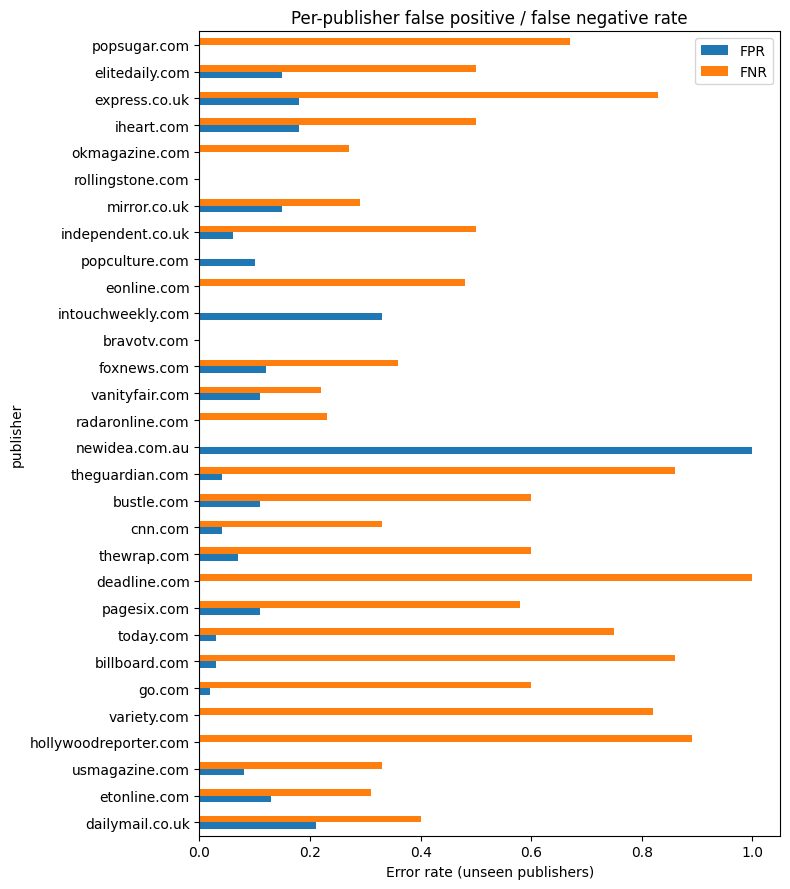

In [28]:
t = pub_table.set_index("publisher")[["FPR", "FNR"]]
ax = t.plot(kind="barh", figsize=(8, max(4, 0.3 * len(t))))
ax.set_xlabel("Error rate (unseen publishers)")
ax.set_title("Per-publisher false positive / false negative rate")
plt.tight_layout()
plt.savefig("phase4_chart_publishers.png", dpi=150)
plt.show()

### B3. Bias between sources (GossipCop vs PolitiFact)

In [29]:
for split_name in ["random", "held-out"]:
    print(f"\n{split_name} split:")
    print(group_report(df, pred_body[split_name][0], "source", 1).to_string())


random split:
       source     n  fake_rate  pred_fake_rate   FPR   FNR   acc
0   gossipcop  1951       0.24            0.22  0.09  0.39  0.83
1  politifact   144       0.51            0.21  0.07  0.66  0.62

held-out split:
       source     n  fake_rate  pred_fake_rate   FPR   FNR   acc
0   gossipcop  1951       0.24            0.22  0.10  0.40  0.83
1  politifact   144       0.51            0.20  0.04  0.65  0.65


### B4. Which words does the model rely on?
We train on all the data and look at the 50 strongest words/phrases for each class. Then we count how many are **part of a publisher's name** (e.g. a word from `dailymail.co.uk`). Many publisher words in the top features means the model has learned the outlet. The masked version should have fewer.

In [30]:
publisher_tokens = set()
for p in df["publisher"].unique():
    for tok in re.split(r"[.\-]", p):
        if len(tok) > 3:
            publisher_tokens.add(tok)


def top_features(col, n=50):
    vec = new_vectorizer()
    X = vec.fit_transform(df[col])
    model = LogisticRegression(C=1.0, max_iter=1000, class_weight="balanced").fit(X, df["y"])
    names = np.array(vec.get_feature_names_out())
    order = np.argsort(model.coef_[0])
    return names[order[-n:]][::-1], names[order[:n]]       # fake-leaning, real-leaning


for label, col in [("PLAIN body text", "article_text"), ("MASKED body text", "article_text_masked")]:
    fake_f, real_f = top_features(col)
    hits = [f for f in list(fake_f) + list(real_f) if any(w in publisher_tokens for w in f.split())]
    print(f"\n=== {label} ===")
    print("Top 15 'fake' features:", list(fake_f[:15]))
    print("Top 15 'real' features:", list(real_f[:15]))
    print(f"Publisher-name words among the top 100 features: {len(hits)}")
    print("Examples:", hits[:15])


=== PLAIN body text ===
Top 15 'fake' features: ['source', 'trump', 'brad', 'kanye', 'insider', 'jenner', 'pitt', 'the source', 'justin', 'shelton', 'jolie', 'has', 'meghan', 'kardashian', 'victoria']
Top 15 'real' features: ['season', 'on', 'the show', 'best', 'me', 'series', 'we', 'episode', 'show', 'black', 'see', 'for', 'brown', 'paul', 'my']
Publisher-name words among the top 100 features: 4
Examples: ['radaronline', 'radaronline com', 'online', 'look']

=== MASKED body text ===
Top 15 'fake' features: ['source', 'trump', 'brad', 'kanye', 'insider', 'jenner', 'pitt', 'the source', 'justin', 'shelton', 'has', 'jolie', 'meghan', 'kardashian', 'victoria']
Top 15 'real' features: ['season', 'on', 'the show', 'best', 'me', 'series', 'we', 'episode', 'show', 'black', 'see', 'brown', 'for', 'paul', 'my']
Publisher-name words among the top 100 features: 2
Examples: ['online', 'look']
